# FitzHugh-Nagumo Model
This notebook demonstrates the FitzHugh-Nagumo model, a simplification of the Hodgkin-Huxley model that captures the essential dynamics of spike generation.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from brian2 import *
%matplotlib inline

## Model Definition
We define the equations and parameters.

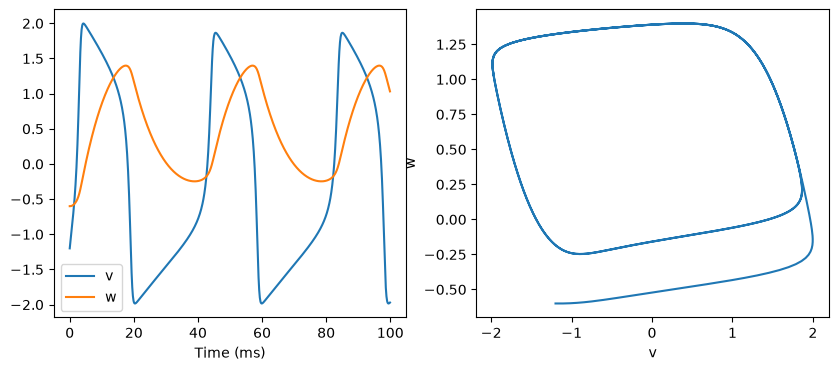

In [2]:
start_scope()
a = 0.7
b = 0.8
tau = 12.5
eqs = '''
dv/dt = (v - v**3/3 - w + I) / ms : 1
dw/dt = (v + a - b * w) / tau / ms : 1
I : 1
'''
G = NeuronGroup(1, eqs, method='euler')
G.v = -1.2
G.w = -0.6
G.I = 0.5
M = StateMonitor(G, ('v', 'w'), record=True)
run(100*ms)
plt.figure(figsize=(10, 4))
plt.subplot(121)
plt.plot(M.t/ms, M.v[0], label='v')
plt.plot(M.t/ms, M.w[0], label='w')
plt.xlabel('Time (ms)')
plt.legend()
plt.subplot(122)
plt.plot(M.v[0], M.w[0])
plt.xlabel('v')
plt.ylabel('w')
plt.show()